# Handwriting screenshot → InkSight strokes → handwriting-synthesis samples

This notebook runs Google's [InkSight](https://github.com/google-research/inksight) Small-p model on a screenshot of handwriting and turns the digital ink it produces into training samples for the handwriting-synthesis model: `[dx, dy, pen_down, pen_up, eos]` rows, exactly as `03-combine-data.ipynb` writes them.

1. Install the dependencies (the Colab runtime restarts once) and load the model.
2. Upload a screenshot: a word, a line, or a few lines.
3. Find the words with OCR, derender each one with InkSight, and map the ink back onto the screenshot.
4. Rainbow visualisation, InkSight style.
5. Convert every text line into a sample: shift, slant-align, scale and resample to match the training data.
6. Visualise the samples the way the handwriting-synthesis notebooks do, then download `strokes_data.npz` + `texts.json`.

Use a **T4 GPU** runtime (*Runtime ▸ Change runtime type*). Samples accumulate in `dataset` across uploads, so steps 2–5 can be repeated for several screenshots before downloading everything in step 6.

**Screenshot tips.** InkSight sees each word as a 224×224 crop, so give it something to work with: dark ink on a plain light background, words at least ~50 px tall, and a margin around the text. Text rendered in a handwriting-style font works the same way as a photo of real handwriting.

In [ ]:
# @title 1. Install dependencies (Colab only; the runtime restarts once)
import importlib.metadata
import os
import sys
import time


def _already_installed():
    try:
        return (
            importlib.metadata.version("tensorflow") == "2.20.0"
            and importlib.metadata.version("tensorflow-text") == "2.20.1"
            and importlib.metadata.version("python-doctr") == "0.10.0"
        )
    except importlib.metadata.PackageNotFoundError:
        return False


if "google.colab" not in sys.modules:
    print("Not running in Colab; skipping install. Locally, run `uv sync` in the inksight repo.")
elif _already_installed():
    print("Dependencies already installed. Carry on with the next cell.")
else:
    !apt-get -qq update
    !apt-get -qq install --yes tesseract-ocr
    %pip install --quiet \
        "tensorflow[and-cuda]==2.20.0" \
        "tensorflow-text==2.20.1" \
        "tf-keras==2.20.1" \
        "python-doctr[tf,viz]==0.10.0" \
        "pytesseract>=0.3.13"

    print(
        "Dependencies installed. Restarting the runtime... "
        "Once it reconnects, run the cells from the top again (this one now just prints a message).",
        flush=True,
    )
    time.sleep(1)
    os.kill(os.getpid(), 9)

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
transformers 5.21.0 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
ydf-tf 2.21.0 requires tensorflow==2.2

In [1]:
# @title 2. Configure TensorFlow and import docTR
import os

# The released checkpoint needs the pre-2.18 XLA GEMM lowering (see the InkSight repo's
# colab.ipynb). The flags have to be in place before TensorFlow is imported.
_inksight_xla_flags = (
    "--xla_gpu_autotune_level=0 "
    "--xla_disable_hlo_passes=custom-kernel-fusion-rewriter,custom_kernel-fusion-autotuner"
)
if _inksight_xla_flags not in os.environ.get("XLA_FLAGS", ""):
    os.environ["XLA_FLAGS"] = f'{os.environ.get("XLA_FLAGS", "")} {_inksight_xla_flags}'.strip()

# docTR with its TensorFlow backend (it pins tf.keras to Keras 2 for itself; InkSight's
# SavedModel does not care). Import it before TensorFlow, as the InkSight notebook does.
os.environ["USE_TF"] = "1"
from doctr.io import DocumentFile
from doctr.models import ocr_predictor

import pytesseract
import tensorflow as tf
import tensorflow_text  # noqa: F401  registers the text ops the InkSight SavedModel uses

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow", tf.__version__, "| GPU:", ", ".join(g.name for g in gpus) or "none (inference will be slow)")

/Users/jacob/github.com/jda5/handwriting-synthesis/.venv/lib/python3.13/site-packages/doctr/file_utils.py:86: DeprecationWarning: Support for TensorFlow in DocTR is deprecated and will be removed in the next major release (v1.0.0). Please switch to the PyTorch backend.
  warnings.warn(


TensorFlow 2.21.0 | GPU: none (inference will be slow)


In [2]:
# @title 3. Load InkSight Small-p
# `from_pretrained_keras` was removed in huggingface_hub 1.0, so the SavedModel is downloaded
# and loaded directly. Only its serving signature is needed.
from huggingface_hub import snapshot_download

MODEL_DIR = snapshot_download("Derendering/InkSight-Small-p")
inksight = tf.saved_model.load(MODEL_DIR)
derender_fn = inksight.signatures["serving_default"]

print("Loaded InkSight Small-p from", MODEL_DIR)
print("Signature inputs:", list(derender_fn.structured_input_signature[1]))

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Loaded InkSight Small-p from /Users/jacob/.cache/huggingface/hub/models--Derendering--InkSight-Small-p/snapshots/8514f237f318b83fe3d27c49989daaa4de9dabb9
Signature inputs: ['input_text', 'image_encoded']


In [3]:
# @title 4. InkSight helpers: ink tokens, image preparation, word segmentation, inference, rainbow plot
import colorsys
import io
import re
import time
from dataclasses import dataclass

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.patheffects import withStroke
from PIL import Image, ImageEnhance

IMAGE_SIZE = 224  # InkSight reads and writes 224x224 images

PROMPT_DERENDER = "Derender the ink."
PROMPT_RECOGNISE = "Recognize and derender."
PROMPT_WITH_TEXT = "Derender the ink: {}"


class Stroke:
    """One pen-down stroke: parallel lists of x and y coordinates (y grows downwards)."""

    def __init__(self, list_of_coordinates=None):
        self.x, self.y = [], []
        for x, y in list_of_coordinates or []:
            self.x.append(x)
            self.y.append(y)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, index):
        return (self.x[index], self.y[index])


class Ink:
    """A list of strokes in writing order."""

    def __init__(self, list_of_strokes=None):
        self.strokes = list(list_of_strokes or [])

    def __len__(self):
        return len(self.strokes)

    def __getitem__(self, index):
        return self.strokes[index]


# ---- Ink tokens ----------------------------------------------------------------------------
# The model writes ink as text: <ink_token_450> starts a stroke, then alternating x tokens
# (0..224) and y tokens (225..449). Anything else in the output is text it recognised.


def text_to_tokens(text):
    return [int(tok) for tok in re.findall(r"<ink_token_(\d+)>", text)]


def strip_ink_tokens(text):
    """The text around the ink tokens: the recognised word in 'Recognize and derender.' mode.
    Sentinel tokens such as <extra_id_0>, which the model puts in front of it, go too."""
    return re.sub(r"<[^<>]*>", "", text).strip()


def detokenize(tokens):
    """Ink tokens -> Ink in 224x224 coordinates (verbatim from the InkSight notebook)."""
    coordinate_length = IMAGE_SIZE
    num_token_per_dimension = coordinate_length + 1
    vocabulary_size = num_token_per_dimension * 2 + 1
    start_token = num_token_per_dimension * 2

    if any(t < 0 or t >= vocabulary_size for t in tokens):
        raise ValueError(f"Ink token indices should be between 0 and {vocabulary_size}")

    idx, res, current_stroke_tokens = 0, [], []
    while idx < len(tokens):
        token = tokens[idx]
        if token == start_token:
            if current_stroke_tokens:
                res.append(current_stroke_tokens)
            current_stroke_tokens = []
            idx += 1
        elif idx + 1 < len(tokens) and tokens[idx + 1] != start_token:
            x = tokens[idx]
            y = tokens[idx + 1] - num_token_per_dimension
            if 0 <= x <= coordinate_length and 0 <= y <= coordinate_length:
                current_stroke_tokens.append([x, y])
            idx += 2
        else:
            idx += 1  # an x with no y: skip it
    if current_stroke_tokens:
        res.append(current_stroke_tokens)

    return Ink([Stroke([(x, y) for x, y in stroke]) for stroke in res])


# ---- Images ---------------------------------------------------------------------------------


def to_rgb(image):
    """Flatten transparency onto white (screenshots are often RGBA) and return an RGB image."""
    if image.mode in ("RGBA", "LA") or (image.mode == "P" and "transparency" in image.info):
        image = image.convert("RGBA")
        background = Image.new("RGBA", image.size, (255, 255, 255, 255))
        return Image.alpha_composite(background, image).convert("RGB")
    return image.convert("RGB")


def scale_and_pad(image, size=IMAGE_SIZE, pad_colour=(0, 0, 0)):
    """Scale an image to fit a size x size square (keeping its aspect ratio) and centre it on
    black, as InkSight expects. Returns the padded image and (ratio, dx, dy) for map_back()."""
    image = image.convert("RGB")
    ratio = min(size / image.width, size / image.height)
    resized = image.resize((max(1, int(image.width * ratio)), max(1, int(image.height * ratio))))
    padded = Image.new("RGB", (size, size), pad_colour)
    dx = (size - resized.width) // 2
    dy = (size - resized.height) // 2
    padded.paste(resized, (dx, dy))
    return padded, (ratio, dx, dy)


def map_back(ink, ratio, dx, dy, x0, y0):
    """Ink in 224x224 crop coordinates -> screenshot pixel coordinates."""
    return Ink(
        Stroke([((x - dx) / ratio + x0, (y - dy) / ratio + y0) for x, y in zip(stroke.x, stroke.y)])
        for stroke in ink.strokes
    )


# ---- Word segmentation ----------------------------------------------------------------------


@dataclass
class Word:
    box: tuple  # (x0, y0, x1, y1) in screenshot pixels
    ocr_text: str  # what the OCR engine read; unreliable on handwriting, so only a fallback
    line: int  # index of the text line the word sits on, top to bottom


def group_into_lines(boxes, min_overlap=0.4):
    """Group (x0, y0, x1, y1, text) boxes into text lines by vertical overlap, top to bottom,
    words left to right. The OCR engines' own line/block grouping is not used, because docTR
    sometimes puts the last word of a line into a block of its own."""
    lines = []
    for box in sorted(boxes, key=lambda b: (b[1] + b[3]) / 2):
        for line in lines:
            top = np.median([b[1] for b in line])
            bottom = np.median([b[3] for b in line])
            overlap = min(box[3], bottom) - max(box[1], top)
            if overlap > min_overlap * min(box[3] - box[1], bottom - top):
                line.append(box)
                break
        else:
            lines.append([box])
    lines.sort(key=lambda line: np.median([(b[1] + b[3]) / 2 for b in line]))
    return [sorted(line, key=lambda b: b[0]) for line in lines]


def merge_punctuation(line):
    """Attach a box the OCR read as punctuation only (no letters or digits), such as a comma or
    a full stop it split off, to the word on its left, as the text would write it."""
    merged = []
    for box in line:
        if merged and not re.search(r"[^\W_]", box[4]):
            prev = merged[-1]
            merged[-1] = (min(prev[0], box[0]), min(prev[1], box[1]), max(prev[2], box[2]), max(prev[3], box[3]), prev[4] + box[4])
        else:
            merged.append(box)
    return merged


def find_words(image, engine="doctr", pad=0.1):
    """Find word boxes with docTR or Tesseract. Returns the words in reading order (lines top to
    bottom, words left to right), each box grown by `pad` of its size so ascenders and
    descenders are not clipped (as in the InkSight full-page pipeline)."""
    width, height = image.size
    boxes = []  # (x0, y0, x1, y1, text) in pixels

    if engine == "doctr":
        global _doctr_predictor
        if "_doctr_predictor" not in globals():
            _doctr_predictor = ocr_predictor(pretrained=True)
        buffer = io.BytesIO()
        image.save(buffer, format="PNG")
        result = _doctr_predictor(DocumentFile.from_images(buffer.getvalue()))
        for block in result.pages[0].blocks:
            for line in block.lines:
                for word in line.words:
                    if word.value.strip():
                        (x0, y0), (x1, y1) = word.geometry
                        boxes.append((x0 * width, y0 * height, x1 * width, y1 * height, word.value))
    elif engine == "tesseract":
        data = pytesseract.image_to_data(image, output_type=pytesseract.Output.DICT)
        for i, text in enumerate(data["text"]):
            if text.strip():
                x, y, w, h = data["left"][i], data["top"][i], data["width"][i], data["height"][i]
                boxes.append((x, y, x + w, y + h, text))
    else:
        raise ValueError(f"Unknown OCR engine {engine!r}; use 'doctr' or 'tesseract'")

    found = []
    for line_index, line in enumerate(group_into_lines(boxes)):
        for x0, y0, x1, y1, text in merge_punctuation(line):
            px, py = (x1 - x0) * pad, (y1 - y0) * pad
            box = (
                int(max(0, x0 - px)),
                int(max(0, y0 - py)),
                int(min(width, x1 + px)),
                int(min(height, y1 + py)),
            )
            found.append(Word(box, text, line_index))
    return found


# ---- Stray dots -----------------------------------------------------------------------------

DOT_CHARACTERS = set("ij.:;!?'\"")  # characters whose glyph includes a detached dot or tick


def stroke_length(stroke):
    xy = np.array([stroke.x, stroke.y], dtype=float).T
    return float(np.hypot(*np.diff(xy, axis=0).T).sum()) if len(xy) > 1 else 0.0


def ink_height(ink):
    ys = [y for s in ink.strokes for y in s.y]
    return (max(ys) - min(ys)) if ys else 0.0


def remove_edge_marks(ink, content, edge=4, max_length=0.12):
    """Drop the marks the model writes at the very edge of its input image. In practice these
    are single points at x = 1 or x = 223, where a wide word's image meets the side of the
    224x224 crop, and they are not in the screenshot at all. `content` is (x0, y0, x1, y1), the
    part of the crop the word's image fills (the rest is black padding). A stroke is dropped
    when it is shorter than `max_length` x the word's ink height and every one of its points
    lies within `edge` pixels of the same side of the content. Works in crop coordinates.
    Returns (kept ink, dropped strokes)."""
    if len(ink) < 2:
        return ink, []
    height = ink_height(ink) or 1.0
    x0, y0, x1, y1 = content
    kept, dropped = [], []
    for stroke in ink.strokes:
        x, y = np.array(stroke.x, dtype=float), np.array(stroke.y, dtype=float)
        at_edge = (x <= x0 + edge).all() or (x >= x1 - edge).all() or (y <= y0 + edge).all() or (y >= y1 - edge).all()
        (dropped if at_edge and stroke_length(stroke) < max_length * height else kept).append(stroke)
    if not kept:
        return ink, []
    return Ink(kept), dropped


def remove_stray_dots(ink, text, max_length=0.12):
    """A second, count-based check for stray dots inside the word. A stroke shorter than
    `max_length` x the word's ink height counts as a dot. The word keeps as many dots as its
    text has characters that need one (i, j, punctuation), choosing the dots closest to the
    rest of the ink; the others are dropped. Returns (kept ink, dropped strokes)."""
    if len(ink) < 2:
        return ink, []
    height = ink_height(ink) or 1.0
    tiny = [i for i, s in enumerate(ink.strokes) if stroke_length(s) < max_length * height]
    expected = sum(c in DOT_CHARACTERS for c in text)
    real = [i for i in range(len(ink)) if i not in tiny]
    if len(tiny) <= expected or not real:
        return ink, []

    real_points = np.array([(x, y) for i in real for x, y in zip(ink[i].x, ink[i].y)], dtype=float)

    def distance_to_ink(i):
        own = np.array([ink[i].x, ink[i].y], dtype=float).T
        return np.hypot(*(own[:, None, :] - real_points[None, :, :]).T).min()

    keep = set(sorted(tiny, key=distance_to_ink)[:expected])
    dropped = [i for i in tiny if i not in keep]
    return Ink(s for i, s in enumerate(ink.strokes) if i not in dropped), [ink[i] for i in dropped]


# ---- Inference ------------------------------------------------------------------------------


def derender(images, prompts, batch_size=16, fallback_prompt=PROMPT_DERENDER):
    """Run InkSight on 224x224 images. Returns one (Ink, raw_output_text) per image. Images
    that come back without any ink are retried with the vanilla prompt, as in the InkSight
    notebook."""
    encoded = [tf.io.encode_jpeg(np.array(image.convert("RGB"))) for image in images]
    results = [None] * len(images)

    def run(indexes, prompt_for):
        for start in range(0, len(indexes), batch_size):
            batch = indexes[start : start + batch_size]
            output = derender_fn(
                **{
                    "input_text": tf.constant([prompt_for(i) for i in batch], dtype=tf.string),
                    "image/encoded": tf.reshape(tf.stack([encoded[i] for i in batch]), (len(batch), 1)),
                }
            )
            for i, raw in zip(batch, output["output_0"].numpy()[:, 0]):
                raw = raw.decode()
                results[i] = (detokenize(text_to_tokens(raw)), raw)

    run(list(range(len(images))), lambda i: prompts[i])

    empty = [i for i, (ink, _) in enumerate(results) if len(ink) == 0]
    if empty:
        print(f"{len(empty)} image(s) came back without ink; retrying with {fallback_prompt!r}")
        run(empty, lambda i: fallback_prompt)
    return results


# ---- Rainbow plot ---------------------------------------------------------------------------


def plot_ink(ink, ax, lw=1.8, input_image=None, with_path=True, path_color="white", size=None):
    """InkSight's rainbow plot: strokes coloured in writing order, fading along each stroke,
    over a darkened copy of the input image. `size` = (width, height) of the coordinate space,
    taken from the image when one is given, else 224x224."""
    if input_image is not None:
        ax.imshow(ImageEnhance.Brightness(input_image).enhance(0.45))
    width, height = size or (input_image.size if input_image is not None else (IMAGE_SIZE, IMAGE_SIZE))

    base_colors = plt.get_cmap("rainbow", max(len(ink.strokes), 1))
    for i, stroke in enumerate(ink.strokes):
        x, y = np.array(stroke.x, dtype=float), np.array(stroke.y, dtype=float)
        base_color = base_colors(len(ink.strokes) - 1 - i)
        h, s, v = colorsys.rgb_to_hsv(*base_color[:3])
        darker = colorsys.hsv_to_rgb(h, s, max(0, v * 0.65))

        if len(x) < 2:  # a lone point: draw a dot
            ax.plot(x, y, ".", color=darker, markersize=lw * 2)
            continue

        colors = [mcolors.to_rgba(darker, alpha=1 - (0.5 * j / len(x))) for j in range(len(x))]
        points = np.array([x, y]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        lc = LineCollection(segments, colors=colors, linewidth=lw)
        if with_path:
            lc.set_path_effects([withStroke(linewidth=lw * 1.25, foreground=path_color)])
        ax.add_collection(lc)

    ax.set_xlim(0, width)
    ax.set_ylim(height, 0)  # y grows downwards, like image pixels
    ax.set_xticks([])
    ax.set_yticks([])


print("Helpers defined.")

Helpers defined.


/Users/jacob/github.com/jda5/handwriting-synthesis/data/synthetic/images/corpus-0001.png: 1481 x 128 px


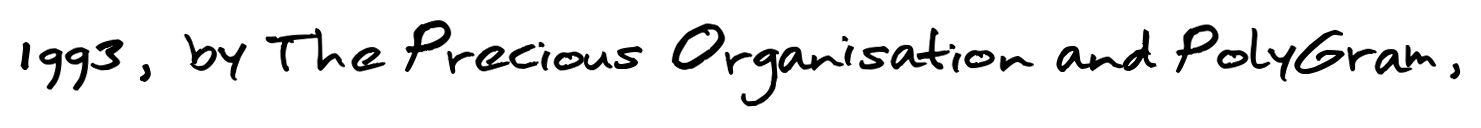

In [5]:
# @title 5. Upload a screenshot
# @markdown Upload a PNG or JPG of a word, a line, or a few lines of handwriting. Outside Colab the InkSight test word is used instead.
from IPython.display import display

try:
    from google.colab import files

    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("No file was uploaded; run this cell again.")
    FILENAME = next(iter(uploaded))
    screenshot = to_rgb(Image.open(io.BytesIO(uploaded[FILENAME])))
except ImportError:
    FILENAME = "/Users/jacob/github.com/jda5/handwriting-synthesis/data/synthetic/images/corpus-0001.png"
    screenshot = to_rgb(Image.open(FILENAME))

print(f"{FILENAME}: {screenshot.width} x {screenshot.height} px")
display(screenshot)

In [ ]:
# @title 6. Derender the screenshot with InkSight
# @markdown **TEXT**: what the screenshot says (optional, but recommended when you know it). When its words line up one-to-one with the words the OCR finds, every word is derendered with the `Derender the ink: <word>` prompt, which is the mode InkSight does best in, and TEXT becomes the sample's label. Otherwise the model recognises the text itself (`Recognize and derender.`).
TEXT = "1993, by The Precious Organisation and PolyGram,"  # @param {type:"string"}
# @markdown **SEGMENT_WORDS**: find the words with OCR and derender each one separately. Needed for lines and pages, because the model only ever sees a 224×224 image. Untick it for a screenshot of a single word, which then goes to the model whole.
SEGMENT_WORDS = True  # @param {type:"boolean"}
OCR_ENGINE = "doctr"  # @param ["doctr", "tesseract"]
# @markdown **DROP_STRAY_DOTS**: the model often writes a single point at the far left or right edge of a word's 224×224 crop, which is not in the screenshot. Tiny marks touching the edge of the word's image are dropped. As a second check, each word keeps only as many other tiny strokes as its text has characters with a detached dot (i, j, punctuation). Dropped marks show as red crosses in step 7.
DROP_STRAY_DOTS = True  # @param {type:"boolean"}

TEXT = TEXT.strip()

if SEGMENT_WORDS:
    words = find_words(screenshot, OCR_ENGINE)
    if not words:
        raise RuntimeError(
            "The OCR found no words. Try the other OCR_ENGINE, a larger or cleaner screenshot, "
            "or untick SEGMENT_WORDS for a single word."
        )
    n_lines = len({word.line for word in words})
    print(f"OCR found {len(words)} word(s) on {n_lines} line(s):", " | ".join(word.ocr_text for word in words))
else:
    words = [Word((0, 0, screenshot.width, screenshot.height), TEXT, 0)]

# Prompts and labels: the given text if it can be matched to the words, else recognition
given_words = TEXT.split()
if TEXT and not SEGMENT_WORDS:
    labels = [TEXT]
    prompts = [PROMPT_WITH_TEXT.format(TEXT)]
elif TEXT and len(given_words) == len(words):
    labels = given_words
    prompts = [PROMPT_WITH_TEXT.format(word) for word in given_words]
else:
    if TEXT:
        print(
            f"TEXT has {len(given_words)} word(s) but the OCR found {len(words)}, so the words cannot be "
            "matched up one to one. Derendering with the model's own recognition instead."
        )
    labels = None
    prompts = [PROMPT_RECOGNISE] * len(words)

# Crop, scale and pad every word, run the model, and map the ink back onto the screenshot
crops, transforms, contents = [], [], []
for word in words:
    crop = screenshot.crop(word.box)
    padded, (ratio, dx, dy) = scale_and_pad(crop)
    crops.append(padded)
    transforms.append((ratio, dx, dy, word.box[0], word.box[1]))
    # The part of the 224x224 crop the word's image fills; the rest is black padding
    contents.append((dx, dy, dx + max(1, int(crop.width * ratio)), dy + max(1, int(crop.height * ratio))))

started = time.perf_counter()
results = derender(crops, prompts)
print(f"Derendered {len(crops)} word(s) in {time.perf_counter() - started:.1f}s")

word_texts = labels or [strip_ink_tokens(raw) or word.ocr_text for (_, raw), word in zip(results, words)]

# Clean each word's ink in crop coordinates, then map it back onto the screenshot
crop_inks = [ink for ink, _ in results]
dropped_strokes = [[] for _ in results]  # drawn as red crosses in step 7
if DROP_STRAY_DOTS:
    for i, (ink, text, content) in enumerate(zip(crop_inks, word_texts, contents)):
        ink, at_edge = remove_edge_marks(ink, content)
        ink, extra = remove_stray_dots(ink, text)
        crop_inks[i] = ink
        dropped_strokes[i] = at_edge + extra
    summary = [f"{text} ({len(d)})" for text, d in zip(word_texts, dropped_strokes) if d]
    if summary:
        print("Stray marks dropped:", ", ".join(summary))

word_inks = [map_back(ink, *transform) for ink, transform in zip(crop_inks, transforms)]

# One Ink per text line, strokes in reading order. Each line becomes one dataset sample.
# A single line is labelled with TEXT whenever it was given, even if its words could not be
# matched to the OCR's, since it is the ground truth.
lines = []
line_indexes = sorted({word.line for word in words})
for line_index in line_indexes:
    members = [i for i, word in enumerate(words) if word.line == line_index]
    text = TEXT if TEXT and len(line_indexes) == 1 else " ".join(word_texts[i] for i in members)
    lines.append(
        {
            "text": text,
            "ink": Ink(stroke for i in members for stroke in word_inks[i].strokes),
            "words": members,
        }
    )

print("\nRaw model output for the first word:", repr(results[0][1][:160]), "...\n")
for i, line in enumerate(lines):
    n_points = sum(len(stroke) for stroke in line["ink"].strokes)
    print(f"Line {i}: {len(line['ink'])} strokes, {n_points} points -> {line['text']!r}")

/Users/jacob/github.com/jda5/handwriting-synthesis/.venv/lib/python3.13/site-packages/gast/astn.py:23: DeprecationWarning: Attribute.__init__ got an unexpected keyword argument '___pyct_anno'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  new_node = cls(
/Users/jacob/github.com/jda5/handwriting-synthesis/.venv/lib/python3.13/site-packages/gast/astn.py:23: DeprecationWarning: Constant.__init__ got an unexpected keyword argument '___pyct_anno'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  new_node = cls(
/Users/jacob/github.com/jda5/handwriting-synthesis/.venv/lib/python3.13/site-packages/gast/astn.py:23: DeprecationWarning: Compare.__init__ got an unexpected keyword argument '___pyct_anno'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  new_node = cls(
/Users/jacob/github.com/jda5/handwriting-synthesis/.venv/lib/python3.13/site-packages/gast/astn.py:2

  0%|          | 0/66552400 [00:00<?, ?it/s]

  0%|          | 0/63386336 [00:00<?, ?it/s]

OCR found 6 word(s) on 1 line(s): 1993, | by | ThePrecious | Organisation | and, | PolyGram,
TEXT has 7 word(s) but the OCR found 6, so the words cannot be matched up one to one. Derendering with the model's own recognition instead.


I0000 00:00:1793705464.692028 8907288 service.cc:153] XLA service 0xb3f744c00 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793705464.692040 8907288 service.cc:161]   StreamExecutor [0]: Host, Default Version (Driver: 0.0.0; Runtime: 0.0.0; Toolkit: 0.0.0; DNN: 0.0.0)
I0000 00:00:1793705464.910906 8907288 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
W0000 00:00:1793705464.996902 8907288 assert_op.cc:39] Ignoring Assert operator jax2tf_unknown_/assert_equal_1/Assert/AssertGuard/Assert
W0000 00:00:1793705465.287281 8907288 assert_op.cc:39] Ignoring Assert operator jax2tf_unknown_/assert_equal_3/Assert/AssertGuard/Assert
W0000 00:00:1793705465.287633 8907288 assert_op.cc:39] Ignoring Assert operator jax2tf_unknown_/assert_equal_5/Assert/AssertGuard/Assert
W0000 00:00:1793705465.288980 8907288 assert_op.cc:39] Ignoring Assert operator jax2tf_unknown_/assert_equal_7/Ass

In [ ]:
# @title 7. Rainbow visualisation (InkSight style)
# @markdown Top: the word crops exactly as the model saw them, with the ink that was kept; red crosses mark stray marks that were dropped. Bottom: the kept ink mapped back onto the screenshot, with the OCR word boxes in red.
LINE_WIDTH = 1.8  # @param {type:"number"}
MAX_WORD_PLOTS = 12  # @param {type:"integer"}

shown = min(len(crops), MAX_WORD_PLOTS)
cols = min(shown, 4)
rows = -(-shown // cols)
fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.4 * rows), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, crop, ink, dropped, text in zip(axes.flat, crops, crop_inks, dropped_strokes, word_texts):
    ax.axis("on")
    plot_ink(ink, ax, lw=LINE_WIDTH, input_image=crop)
    for stroke in dropped:
        ax.plot(stroke.x, stroke.y, "x", color="red", markersize=7, markeredgewidth=2, clip_on=False)
    note = f", {len(dropped)} dropped" if dropped else ""
    ax.set_title(f"{text}  ({len(ink)} strokes{note})", fontsize=10)
fig.suptitle("Word crops (224x224) and their ink", y=1.0)
plt.tight_layout()
plt.show()

width, height = screenshot.size
fig_width = 14
fig, ax = plt.subplots(figsize=(fig_width, max(2.5, fig_width * height / width)))
ax.imshow(ImageEnhance.Brightness(screenshot).enhance(0.45))
for line in lines:
    plot_ink(line["ink"], ax, lw=LINE_WIDTH, size=screenshot.size)
for word in words:
    x0, y0, x1, y1 = word.box
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", linewidth=0.6, alpha=0.6))
ax.set_title(" | ".join(line["text"] for line in lines))
plt.tight_layout()
plt.show()

## From ink to handwriting-synthesis samples

The training data is a list of float32 arrays of shape `(N, 5)` with rows `[dx, dy, pen_down, pen_up, eos]`: the first row is the start token `[0, 0, 1, 0, 0]`, the last is `[0, 0, 0, 0, 1]`, and the point at which the pen lifts carries `pen_up = 1`. In `03-combine-data.ipynb` every sample is shifted, slant-aligned, and divided by its dataset's median *handwriting scale* (the interquartile range of the points' heights about a Theil–Sen baseline), so one unit is roughly the height of the main body of the letters.

InkSight gives absolute pixel coordinates with no timing, so a line of its ink goes through the same steps, with two differences:

- **Scale** is taken from the line itself, so every converted sample has a handwriting scale of exactly 1. The training samples sit between about 0.8 and 1.25.
- **Resampling.** InkSight spaces points by shape, while the training data was sampled in time (about 20 points per character, a median of 0.19 units between consecutive pen-down points). Each stroke is re-spaced along its length to `TARGET_STEP` units so the `dx, dy` the model learns look alike.

Every stroke's last point becomes a pen lift; a single-point stroke (an i-dot or a full stop) becomes a pen-down and a pen-up at the same spot, as the DeepWriting export does. `remove_artifacts` from the cleaning notebooks is not applied: InkSight output has no capture artifacts, and a stray stroke from the model is better judged by eye in the plots below.

In [7]:
# @title 8. Convert each line of ink into a sample
# @markdown **TARGET_STEP**: distance between consecutive pen-down points, in handwriting-scale units (training data: median 0.19, interquartile range 0.11–0.30). Set it to 0 to keep InkSight's own points.
TARGET_STEP = 0.19  # @param {type:"number"}
ALIGN = True  # @param {type:"boolean"}

import json
from typing import NamedTuple

from scipy.stats import theilslopes


class Point(NamedTuple):
    x: float
    y: float
    pen_up: bool


eos_token = (0, 0, 0, 0, 1)

# ---- Verbatim from 03-combine-data.ipynb -----------------------------------------------------


def calculate_strokes(points: list[Point], include_eos: bool = True) -> np.ndarray:
    strokes = []
    prev_x, prev_y = None, None

    for point in points:
        dx = 0 if prev_x is None else point.x - prev_x
        dy = 0 if prev_y is None else point.y - prev_y
        strokes.append((dx, dy, not point.pen_up, point.pen_up, 0))
        prev_x, prev_y = point.x, point.y

    if include_eos:
        strokes.append(eos_token)

    return np.array(strokes, dtype=np.float32)


def shift_points(points: list[Point]) -> list[Point]:
    min_x = min(p.x for p in points)
    min_y = min(p.y for p in points)
    return [Point(p.x - min_x, p.y - min_y, p.pen_up) for p in points]


def fit_baseline(coords: list[np.ndarray]) -> tuple[float, float]:
    centres = np.array([np.median(c, axis=0) for c in coords])
    if len(centres) > 2:
        slope, offset = theilslopes(centres[:, 1], centres[:, 0])[:2]
    else:
        slope, offset = 0.0, np.median(centres[:, 1])
    return slope, offset


def handwriting_scale(points: list[Point]) -> float:
    strokes, current = [], []
    for point in points:
        current.append(point)
        if point.pen_up:
            strokes.append(np.array([(p.x, p.y) for p in current]))
            current = []
    if current:
        strokes.append(np.array([(p.x, p.y) for p in current]))

    slope, offset = fit_baseline(strokes)
    heights = np.concatenate([c[:, 1] - (slope * c[:, 0] + offset) for c in strokes])
    q1, q3 = np.percentile(heights, [25, 75])
    return q3 - q1


def _align(xy: np.ndarray) -> np.ndarray:
    xy = np.copy(xy)
    x, y = xy[:, 0].reshape(-1, 1), xy[:, 1].reshape(-1, 1)
    design = np.concatenate([np.ones([x.shape[0], 1]), x], axis=1)
    offset, slope = np.linalg.inv(design.T.dot(design)).dot(design.T).dot(y).squeeze()
    theta = np.arctan(slope)
    rotation = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
    return np.dot(xy, rotation) - offset


def align_points(points: list[Point]) -> list[Point]:
    point_array = np.array([[point.x, point.y] for point in points], dtype=np.float32)
    aligned_points = _align(point_array)
    return [Point(x=float(a[0]), y=float(a[1]), pen_up=point.pen_up) for a, point in zip(aligned_points, points)]


# ---- InkSight ink -> Points ------------------------------------------------------------------


def ink_to_points(ink: Ink) -> list[Point]:
    """The last point of every stroke carries the pen lift. A single-point stroke (a dot) becomes
    a pen-down and a pen-up at the same spot, so every stroke starts with the pen down."""
    points = []
    for stroke in ink.strokes:
        coords = [(float(x), float(y)) for x, y in zip(stroke.x, stroke.y)]
        if not coords:
            continue
        if len(coords) == 1:
            coords = coords * 2
        points.extend(Point(x, y, False) for x, y in coords[:-1])
        points.append(Point(*coords[-1], True))
    return points


def resample_points(points: list[Point], step: float) -> list[Point]:
    """Re-space every stroke so consecutive points are `step` apart along it, keeping the first
    and last point of each stroke. Pen-up jumps are left alone."""
    strokes, current = [], []
    for point in points:
        current.append(point)
        if point.pen_up:
            strokes.append(current)
            current = []
    if current:
        strokes.append(current)

    resampled = []
    for stroke in strokes:
        xy = np.array([(p.x, p.y) for p in stroke], dtype=float)
        if len(xy) > 1:  # drop repeated points so the arc length is strictly increasing
            xy = xy[np.concatenate([[True], np.hypot(*np.diff(xy, axis=0).T) > 0])]

        if len(xy) < 2:
            new = np.repeat(xy, 2, axis=0)  # a dot: pen down, pen up
        else:
            distance = np.concatenate([[0.0], np.cumsum(np.hypot(*np.diff(xy, axis=0).T))])
            count = max(2, int(round(distance[-1] / step)) + 1)
            targets = np.linspace(0, distance[-1], count)
            new = np.column_stack([np.interp(targets, distance, xy[:, 0]), np.interp(targets, distance, xy[:, 1])])

        resampled.extend(Point(float(x), float(y), False) for x, y in new[:-1])
        resampled.append(Point(float(new[-1, 0]), float(new[-1, 1]), True))
    return resampled


def ink_to_sample(ink: Ink, target_step: float = TARGET_STEP, align: bool = ALIGN) -> np.ndarray:
    """One line of InkSight ink (screenshot pixels) -> an (N, 5) sample in the training data's units."""
    points = shift_points(ink_to_points(ink))
    if align:
        points = align_points(points)

    pixel_scale = handwriting_scale(points)
    if not pixel_scale > 0:  # e.g. one flat stroke: no spread in height, fall back to the bounding box
        ys = [p.y for p in points]
        pixel_scale = max(max(ys) - min(ys), 1.0)

    if target_step > 0:
        points = resample_points(points, target_step * pixel_scale)
        pixel_scale = handwriting_scale(points) or pixel_scale

    points = shift_points([Point(p.x / pixel_scale, p.y / pixel_scale, p.pen_up) for p in points])
    return calculate_strokes(points)


# ---- Convert this screenshot's lines ------------------------------------------------------------

if "dataset" not in globals():
    dataset = {}  # (filename, line index) -> (sample, text); re-running replaces, new uploads add

converted = []
for i, line in enumerate(lines):
    sample = ink_to_sample(line["ink"])
    converted.append((sample, line["text"]))
    dataset[(FILENAME, i)] = (sample, line["text"])

    coordinates = sample[:-1, :2].cumsum(axis=0)
    characters = max(len(line["text"]), 1)
    print(
        f"Line {i}: {line['text']!r}\n"
        f"  {len(sample)} rows ({int(sample[:, 3].sum())} strokes, "
        f"{sum(len(s) for s in line['ink'].strokes)} InkSight points -> {len(sample) - 2} points, "
        f"{(len(sample) - 2) / characters:.1f} per character), "
        f"{np.ptp(coordinates[:, 0]):.1f} x {np.ptp(coordinates[:, 1]):.1f} units"
    )

print(
    f"\n{len(dataset)} sample(s) in the dataset so far. For reference, a training line has a median of "
    "20 points per character, 1.1 strokes per character, and is about 54 x 5 units."
)

Line 0: 'LE11 2HQ'
  179 rows (13 strokes, 185 InkSight points -> 177 points, 22.1 per character), 14.6 x 2.9 units

1 sample(s) in the dataset so far. For reference, a training line has a median of 20 points per character, 1.1 strokes per character, and is about 54 x 5 units.


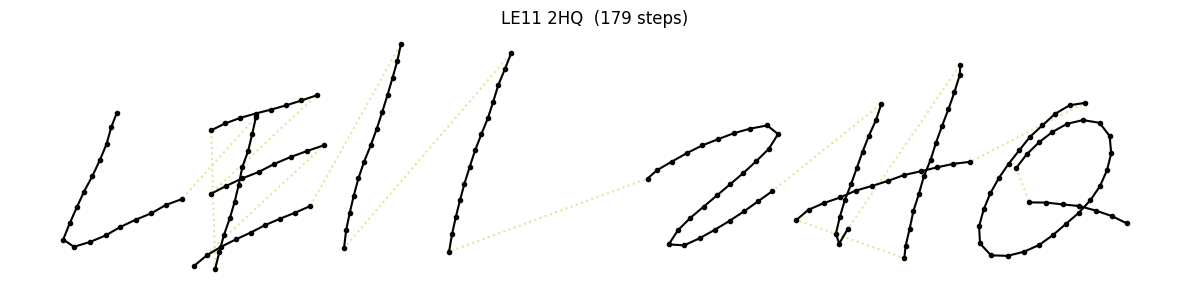

In [8]:
# @title 9. Visualise like the handwriting-synthesis notebooks
# Verbatim from 04-model-improved.ipynb: the yellow dotted line is the pen's whole path, so
# pen-up jumps show as faint gaps between the black pen-down strokes; every point is a dot.


def draw_strokes(strokes: np.ndarray, label: str | None = None):
    coordinates = strokes[:, :2].cumsum(axis=0)
    pen_lifts = np.flatnonzero(strokes[:, 3])

    plt.figure(figsize=(12, 3))
    plt.plot(coordinates[:, 0], -coordinates[:, 1], "y:", alpha=0.4)

    for stroke in np.split(coordinates, pen_lifts + 1)[:-1]:
        plt.plot(stroke[:, 0], -stroke[:, 1], ".-", color="black")

    plt.title(label)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


for sample, text in converted:
    draw_strokes(sample, f"{text}  ({len(sample)} steps)")

In [ ]:
# @title 10. Save and download the dataset
# @markdown Writes `strokes_data.npz` and `texts.json` in the layout `04-model-improved.ipynb` loads, zips the folder, and downloads it. Everything converted since the notebook started is included.
import shutil
from datetime import datetime
from pathlib import Path

if not dataset:
    raise RuntimeError("Nothing to save yet: run steps 5-8 first.")

samples = list(dataset.values())
strokes_data = [sample for sample, _ in samples]
texts = [text for _, text in samples]

# The checks 04-model-improved.ipynb makes when it loads the data
sos = np.array([0, 0, 1, 0, 0], dtype=np.float32)
eos = np.array(eos_token, dtype=np.float32)
assert len(strokes_data) == len(texts)
assert all((s[0] == sos).all() and (s[-1] == eos).all() for s in strokes_data)
assert all(np.isfinite(s).all() for s in strokes_data)

SAVE_DIR = Path(f"inksight-{datetime.now().strftime('%Y-%m-%dT%H-%M-%S')}")
SAVE_DIR.mkdir()
np.savez(SAVE_DIR / "strokes_data.npz", *strokes_data)
with open(SAVE_DIR / "texts.json", "w", encoding="utf-8") as f:
    json.dump(texts, f, ensure_ascii=False, separators=(",", ":"))

# The zip holds the folder itself, so it unpacks into data/cleaned/ as inksight-<timestamp>/
archive = shutil.make_archive(str(SAVE_DIR), "zip", root_dir=SAVE_DIR.parent, base_dir=SAVE_DIR.name)
print(f"Saved {len(samples)} sample(s) to {SAVE_DIR}/ and {archive}")
for text in texts:
    print(" -", repr(text))

try:
    from google.colab import files

    files.download(archive)
except ImportError:
    pass

Saved 1 sample(s) to inksight-2026-10-30T12-23-00/ and /content/inksight-2026-10-30T12-23-00.zip
 - 'Waltz, bad nymph, for quick jigs vex'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Using the samples in handwriting-synthesis

Unzip the download into `data/cleaned/`. `04-model-improved.ipynb` trains on the newest `combined-*` folder, so append the new samples to the latest combined set rather than training on them alone:

```python
import json
from datetime import datetime
from pathlib import Path
import numpy as np

cleaned = Path("data/cleaned")


def load(path):
    with np.load(path / "strokes_data.npz") as data:
        strokes = [data[f"arr_{i}"] for i in range(len(data.files))]
    with open(path / "texts.json") as f:
        return strokes, json.load(f)


base_strokes, base_texts = load(max(cleaned.glob("combined-*")))
new_strokes, new_texts = load(max(cleaned.glob("inksight-*")))

out = cleaned / f"combined-{datetime.now().strftime('%Y-%m-%dT%H-%M-%S')}"
out.mkdir()
np.savez(out / "strokes_data.npz", *base_strokes, *new_strokes)
with open(out / "texts.json", "w", encoding="utf-8") as f:
    json.dump(base_texts + new_texts, f, ensure_ascii=False, separators=(",", ":"))
```

Things to keep in mind:

- These samples are InkSight's guess at how the writing was produced, not recorded pen data. Stroke order and direction are usually plausible but not guaranteed, and a messy derendering is better dropped than kept; the plots in steps 7 and 9 are there to check each one.
- The resampled points are evenly spaced, whereas real pen data slows down in curves and speeds up on straight runs. If that matters, set `TARGET_STEP` to 0 and apply your own resampling.
- New characters extend the vocabulary that `TextVectorization` adapts in `04-model-improved.ipynb`, and a longer line than any in the data raises `text_length`. Both mean training a fresh model rather than fine-tuning a checkpoint whose `config.json` fixed them.
- A handful of samples will not shift what the model has learnt from 16k lines. Rare characters need many examples, in varied contexts and styles, so plan on screenshots of many lines, ideally in several handwriting fonts.